# Comparison

## Setup

In [1]:
from pathlib import Path

import pandas as pd

from src.config import HORIZONS, N_TEST
from src.evaluation import error_metrics, seasonal_naive
from src.visualization import plot_forecasts

DATA_DIR = Path("data")
FIG_DIR = Path("figures/comparison")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def read_csv(name):
    return pd.read_csv(DATA_DIR / name, index_col="date", parse_dates=True)


y = read_csv("model_data.csv")["x"]
y_test = y.iloc[-N_TEST:]
arima = read_csv("arima_forecasts.csv")
recursive = read_csv("ml_recursive_forecasts.csv")
direct = read_csv("ml_direct_forecasts.csv")

In [2]:
rows = []
for h in HORIZONS:
    fc = pd.DataFrame({
        "ARIMA": arima[f"ARIMA_h{h}"],
        "RF recursive": recursive[f"RF_h{h}"],
        "GBM recursive": recursive[f"GBM_h{h}"],
        "RF direct": direct[f"RF_h{h}"],
        "GBM direct": direct[f"GBM_h{h}"],
        "Seasonal naive": seasonal_naive(y, N_TEST, h),
    })
    for model in fc.columns:
        rows.append({"h": h, "model": model, **error_metrics(y_test, fc[model])})

results = pd.DataFrame(rows)
rmse = results.pivot(index="h", columns="model", values="RMSE")[fc.columns]
mae = results.pivot(index="h", columns="model", values="MAE")[fc.columns]
print("RMSE"); display(rmse.round(3))
print("MAE"); display(mae.round(3))
print("RMSE relative to ARIMA (%)"); display((100 * (rmse.div(rmse["ARIMA"], axis=0) - 1)).round(1))


RMSE


model,ARIMA,RF recursive,GBM recursive,RF direct,GBM direct,Seasonal naive
h,,,,,,
1,20.346,23.434,22.682,23.434,22.682,29.482
3,20.661,24.036,23.185,24.288,23.596,29.482
7,21.000,24.564,23.268,23.893,22.888,29.482
14,21.644,26.554,24.654,26.099,24.639,32.918
30,22.514,27.394,26.494,25.860,25.278,32.594


MAE


model,ARIMA,RF recursive,GBM recursive,RF direct,GBM direct,Seasonal naive
h,,,,,,
1,16.223,18.654,18.163,18.654,18.163,22.156
3,16.398,18.968,18.512,19.162,18.788,22.156
7,16.747,19.503,18.540,19.134,18.418,22.156
14,17.229,21.076,19.877,20.772,19.918,25.493
30,18.010,21.801,20.912,20.785,20.641,25.699


RMSE relative to ARIMA (%)


model,ARIMA,RF recursive,GBM recursive,RF direct,GBM direct,Seasonal naive
h,,,,,,
1,0.0,15.2,11.5,15.2,11.5,44.9
3,0.0,16.3,12.2,17.6,14.2,42.7
7,0.0,17.0,10.8,13.8,9.0,40.4
14,0.0,22.7,13.9,20.6,13.8,52.1
30,0.0,21.7,17.7,14.9,12.3,44.8


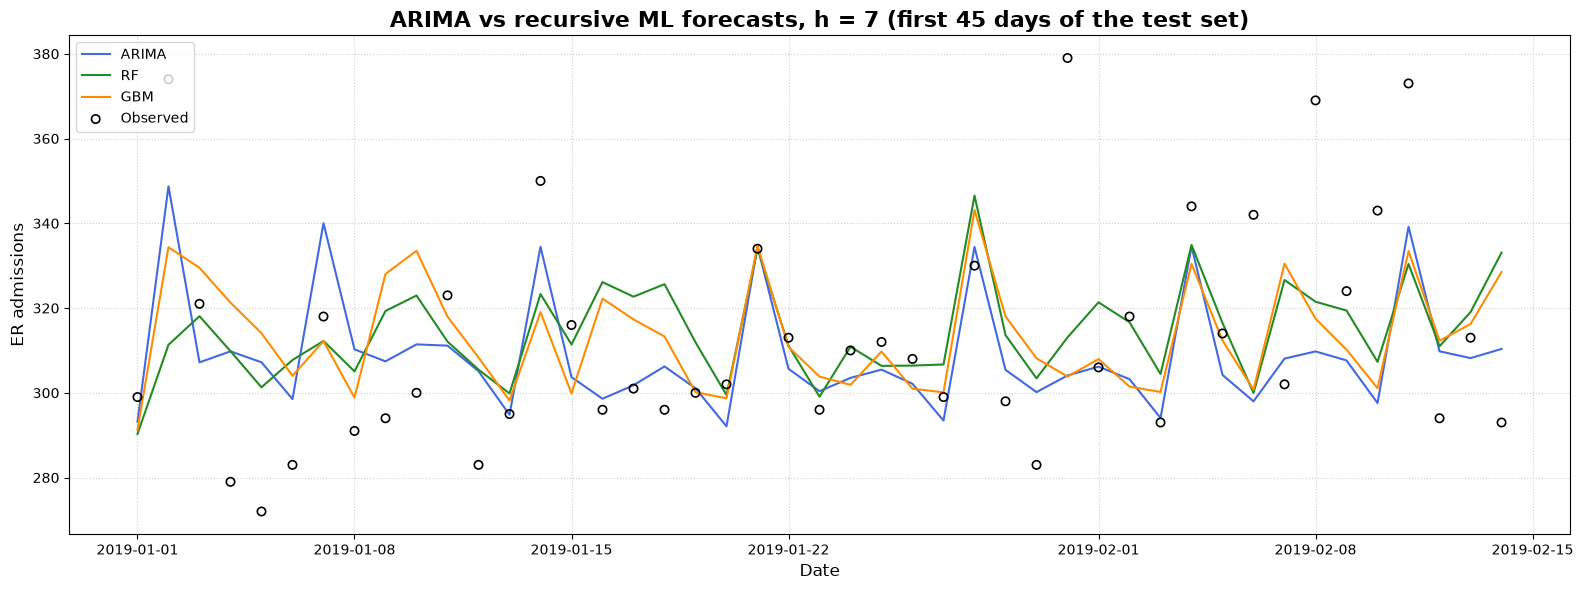

In [3]:
h, days = 7, 45
plot_forecasts(
    y_test.iloc[:days],
    pd.DataFrame({"ARIMA": arima[f"ARIMA_h{h}"], "RF": recursive[f"RF_h{h}"], "GBM": recursive[f"GBM_h{h}"]}).iloc[:days],
    title=f"ARIMA vs recursive ML forecasts, h = {h} (first {days} days of the test set)",
    save_name=FIG_DIR / f"comparison_h{h}.png",
)

## Diebold-Mariano test

In [4]:
import numpy as np
import pandas as pd

from src.diebold_mariano import diebold_mariano

comparisons = [
    ("ARIMA vs RF direct", lambda h: arima[f"ARIMA_h{h}"], lambda h: direct[f"RF_h{h}"]),
    ("ARIMA vs GBM direct", lambda h: arima[f"ARIMA_h{h}"], lambda h: direct[f"GBM_h{h}"]),
    ("ARIMA vs RF recursive", lambda h: arima[f"ARIMA_h{h}"], lambda h: recursive[f"RF_h{h}"]),
    ("ARIMA vs GBM recursive", lambda h: arima[f"ARIMA_h{h}"], lambda h: recursive[f"GBM_h{h}"]),
    ("RF recursive vs RF direct", lambda h: recursive[f"RF_h{h}"], lambda h: direct[f"RF_h{h}"]),
    ("GBM recursive vs GBM direct", lambda h: recursive[f"GBM_h{h}"], lambda h: direct[f"GBM_h{h}"]),
]

dm_records = []
for comp_name, get_f1, get_f2 in comparisons:
    for h in HORIZONS:
        f1 = get_f1(h)
        f2 = get_f2(h)
        for loss in ["SE", "AE"]:
            if np.allclose(f1, f2):
                stat, p_val = 0.0, 1.0
            else:
                res = diebold_mariano(y_test, f1, f2, h=h, loss=loss, alternative="two-sided")
                stat, p_val = res["statistic"], res["p_value"]

            dm_records.append({
                "comparison": comp_name,
                "h": h,
                "loss": loss,
                "statistic": stat,
                "p_value": p_val,
            })

dm_results = pd.DataFrame(dm_records)

# Save full results table to CSV
dm_csv_path = DATA_DIR / "dm_test_results.csv"
dm_results.to_csv(dm_csv_path, index=False)
print(f"Diebold-Mariano test results saved to: {dm_csv_path}")

# Format: statistic (p-value)
comp_order = [c[0] for c in comparisons]
dm_results["formatted"] = dm_results.apply(
    lambda r: f"{r['statistic']:.3f} (p={r['p_value']:.4f})"
    if r["p_value"] >= 0.0001
    else f"{r['statistic']:.3f} (p<0.0001)",
    axis=1,
)

print("\nSquared Error (SE)")
display(
    dm_results[dm_results["loss"] == "SE"]
    .pivot(index="comparison", columns="h", values="formatted")
    .reindex(comp_order)
)

print("\nAbsolute Error (AE)")
display(
    dm_results[dm_results["loss"] == "AE"]
    .pivot(index="comparison", columns="h", values="formatted")
    .reindex(comp_order)
)


Diebold-Mariano test results saved to: data/dm_test_results.csv

Squared Error (SE)


h,1,3,7,14,30
comparison,,,,,
ARIMA vs RF direct,-4.509 (p<0.0001),-4.470 (p<0.0001),-3.615 (p=0.0003),-4.338 (p<0.0001),-2.404 (p=0.0167)
ARIMA vs GBM direct,-4.180 (p<0.0001),-4.985 (p<0.0001),-3.265 (p=0.0012),-4.222 (p<0.0001),-2.080 (p=0.0382)
ARIMA vs RF recursive,-4.509 (p<0.0001),-4.756 (p<0.0001),-3.987 (p<0.0001),-3.895 (p=0.0001),-2.060 (p=0.0401)
ARIMA vs GBM recursive,-4.180 (p<0.0001),-4.722 (p<0.0001),-3.591 (p=0.0004),-3.772 (p=0.0002),-2.802 (p=0.0054)
RF recursive vs RF direct,0.000 (p=1.0000),-0.598 (p=0.5503),1.534 (p=0.1260),0.638 (p=0.5241),1.178 (p=0.2395)
GBM recursive vs GBM direct,0.000 (p=1.0000),-1.640 (p=0.1018),1.336 (p=0.1824),0.032 (p=0.9743),1.049 (p=0.2951)



Absolute Error (AE)


h,1,3,7,14,30
comparison,,,,,
ARIMA vs RF direct,-4.517 (p<0.0001),-5.909 (p<0.0001),-4.159 (p<0.0001),-4.869 (p<0.0001),-3.059 (p=0.0024)
ARIMA vs GBM direct,-4.042 (p<0.0001),-5.350 (p<0.0001),-3.234 (p=0.0013),-4.116 (p<0.0001),-2.616 (p=0.0093)
ARIMA vs RF recursive,-4.517 (p<0.0001),-4.777 (p<0.0001),-4.748 (p<0.0001),-3.958 (p<0.0001),-2.063 (p=0.0398)
ARIMA vs GBM recursive,-4.042 (p<0.0001),-4.697 (p<0.0001),-3.971 (p<0.0001),-4.336 (p<0.0001),-2.608 (p=0.0095)
RF recursive vs RF direct,0.000 (p=1.0000),-0.587 (p=0.5579),0.727 (p=0.4676),0.401 (p=0.6887),0.850 (p=0.3960)
GBM recursive vs GBM direct,0.000 (p=1.0000),-1.034 (p=0.3019),0.410 (p=0.6818),-0.089 (p=0.9287),0.269 (p=0.7882)
